# Solutions to notebook 14: Fourth-order problems: beams, plates and flow stability

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/spectral-methods-in-python/blob/main/solutions/14_fourth_order_problems.ipynb)

Worked solutions to the exercises at the end of [notebook 14](../notebooks/14_fourth_order_problems.ipynb).
Try each exercise yourself before reading its solution: the struggle is where the learning happens.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import eig, eigvals, solve
from scipy.optimize import brentq

plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2, "figure.figsize": (6.4, 4),
})

In [2]:
# cheb(N) from notebook 5
def cheb(N):
    """Chebyshev differentiation matrix D, (N+1) x (N+1), and the points x_j = cos(jπ/N)."""
    if N == 0:
        return np.zeros((1, 1)), np.ones(1)
    j = np.arange(N + 1)
    x = np.cos(np.pi * j / N)
    c = np.where((j == 0) | (j == N), 2.0, 1.0) * (-1.0) ** j
    dx = x[:, None] - x[None, :]
    D = (c[:, None] / c[None, :]) / (dx + np.eye(N + 1))        # the identity avoids 0/0 on the diagonal
    D -= np.diag(D.sum(axis=1))                                  # diagonal from the zero row sums
    return D, x

# barycentric_interpolate(values, x_eval) from notebook 4, used here to draw smooth curves
def barycentric_interpolate(values, x_eval):
    """Evaluate the polynomial interpolant through values at the Chebyshev points."""
    values = np.asarray(values, dtype=float)
    N = len(values) - 1
    j = np.arange(N + 1)
    x = np.cos(np.pi * j / N)
    w = (-1.0) ** j
    w[0] /= 2
    w[N] /= 2
    x_eval = np.atleast_1d(np.asarray(x_eval, dtype=float))
    diff = x_eval[:, None] - x[None, :]
    exact = diff == 0
    diff[exact] = 1.0
    ratio = w / diff
    result = ratio @ values / ratio.sum(axis=1)
    hit_rows, hit_cols = np.nonzero(exact)
    result[hit_rows] = values[hit_cols]
    return result

# laplacian_2d(N) from notebook 6
def laplacian_2d(N):
    """Laplacian on the interior Chebyshev points of the square, zero boundary values. Returns L and x."""
    D, x = cheb(N)
    D2 = (D @ D)[1:N, 1:N]
    I = np.eye(N - 1)
    return np.kron(I, D2) + np.kron(D2, I), x

x_plot = np.linspace(-1, 1, 201)

In [3]:
# functions from notebook 14
def clamped_d4(N):
    """Fourth-derivative matrix on the interior Chebyshev points for functions with u = u' = 0 at x = ±1."""
    D, x = cheb(N)
    D2 = D @ D
    D3, D4 = D2 @ D, D2 @ D2
    weight = np.zeros(N + 1)
    weight[1:-1] = 1 / (1 - x[1:-1] ** 2)                    # q = u / (1 - x²) at the interior points
    operator = (np.diag(1 - x**2) @ D4 - 8 * np.diag(x) @ D3 - 12 * D2) @ np.diag(weight)
    return operator[1:-1, 1:-1]

def orr_sommerfeld(Re, alpha, N, vectors=False):
    """Phase speeds c of disturbances exp(iα(x - ct)) to plane Poiseuille flow (and eigenvectors if asked)."""
    D, y = cheb(N)
    D2 = (D @ D)[1:N, 1:N]
    I = np.eye(N - 1)
    B = D2 - alpha**2 * I                                             # D² - α²
    B_squared = clamped_d4(N) - 2 * alpha**2 * D2 + alpha**4 * I      # (D² - α²)², with v = v' = 0 at the walls
    A = np.diag(1 - y[1:N] ** 2) @ B + 2 * I + 1j / (alpha * Re) * B_squared
    return eig(A, B, right=vectors)

def growth(Re, alpha, N=60):
    """Largest c_i: positive means that some disturbance of wavenumber α grows."""
    return orr_sommerfeld(Re, alpha, N).imag.max()

# the matrix L of 14.5, taken out of clamped_plate so that exercises 3 and 4 can use it
def plate_operator(N):
    """Biharmonic operator on the interior Chebyshev points of the square, clamped on all four edges."""
    D, x = cheb(N)
    D2 = (D @ D)[1:N, 1:N]
    D4 = clamped_d4(N)
    I = np.eye(N - 1)
    return np.kron(I, D4) + np.kron(D4, I) + 2 * np.kron(D2, D2)

## Exercise 1

**The second buckling mode.** With $N = 24$, compute the second and third buckling loads of
the clamped column of 14.4 and plot the first three buckled shapes. The second mode is
antisymmetric, and theory gives $P_2 = k^2$ with $k$ the smallest positive root of
$\tan k = k$ ($k = 4.4934$, $P_2 = 20.1907$). Confirm this to $10^{-8}$ using `brentq` for
the root.

The generalized eigenproblem of 14.4 already delivers all the buckling loads; only the first
was used there. For the theory, the solutions of $w'''' = -k^2w''$ are $1$, $x$, $\cos kx$ and
$\sin kx$. The antisymmetric combination $w = \sin kx - x\sin k$ vanishes at $x = \pm1$, and
its slope there, $k\cos k - \sin k$, vanishes when $\tan k = k$. The symmetric shapes are
$\cos kx - \cos k$, with $\sin k = 0$: $P_1 = \pi^2$ and $P_3 = 4\pi^2$. To keep `brentq`
away from the pole of the tangent, the root is found from $\sin k - k\cos k = 0$ between $\pi$
and $3\pi/2$.

root of tan k = k: k = 4.4934094579
mode   computed P        theory            difference
  1    9.8696044011    9.8696044011    4.0e-11
  2    20.1907285562    20.1907285564    2.7e-10
  3    39.4784176044    39.4784176044    1.8e-11


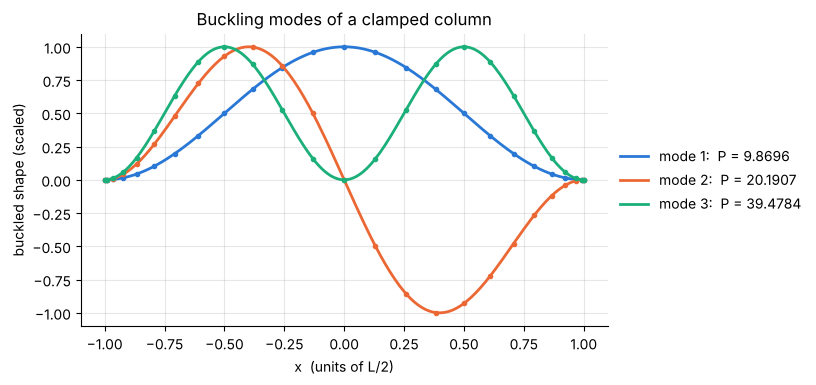

In [4]:
N = 24
D, x = cheb(N)
D2 = (D @ D)[1:N, 1:N]
xi = x[1:N]                                                     # interior points; index 0 of x is x = +1
loads, shapes = eig(clamped_d4(N), -D2)
order = np.argsort(loads.real)
loads, shapes = loads[order].real, shapes[:, order].real

k_root = brentq(lambda k: np.sin(k) - k * np.cos(k), np.pi, 1.5 * np.pi)
theory = np.array([np.pi**2, k_root**2, 4 * np.pi**2])
exact_shapes = [1 + np.cos(np.pi * x_plot), np.sin(k_root * x_plot) - x_plot * np.sin(k_root), 1 - np.cos(2 * np.pi * x_plot)]
print(f"root of tan k = k: k = {k_root:.10f}")
print("mode   computed P        theory            difference")
for m in range(3):
    print(f"  {m + 1}    {loads[m]:.10f}    {theory[m]:.10f}    {abs(loads[m] - theory[m]):.1e}")

fig, ax = plt.subplots(figsize=(6.8, 3.8))
shape_errors = []
for m in range(3):
    shape = np.concatenate([[0], shapes[:, m], [0]])           # add the clamped ends, where w = 0
    curve = barycentric_interpolate(shape, x_plot)
    scale = curve[np.abs(curve).argmax()]
    exact = exact_shapes[m] / exact_shapes[m][np.abs(curve).argmax()]
    shape_errors.append(np.abs(curve / scale - exact).max())
    line, = ax.plot(x_plot, curve / scale, label=f"mode {m + 1}:  P = {loads[m]:.4f}")
    ax.plot(x, shape / scale, "o", ms=3, color=line.get_color())
ax.set(xlabel="x  (units of L/2)", ylabel="buckled shape (scaled)", title="Buckling modes of a clamped column")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5));

In [5]:
# verify: the loads against the roots of the characteristic equations (tan k = k and sin k = 0),
# and the computed shapes against the closed-form buckled shapes
assert abs(k_root - 4.4934) < 1e-4 and abs(np.tan(k_root) - k_root) < 1e-10
assert np.abs(loads[:3] - theory).max() < 1e-8
assert max(shape_errors) < 1e-8

**Answer.** $P_2 = 20.19072856$, equal to $k^2$ with $k = 4.4934094579$ to $3\times10^{-10}$,
and $P_3 = 39.47841760 = 4\pi^2$; the loads are in units of $EI/(L/2)^2$. In the original
units $P_2 = 80.76\,EI/L^2$, 2.046 times the critical load. The second mode matters in
practice when the first is suppressed: a brace at mid-height holds the column at the node of
the antisymmetric shape, so the braced column buckles in mode 2 and carries about twice the
load.

## Exercise 2

**A beam on an elastic foundation.** A clamped beam resting on a bed of springs (a railway
sleeper, a strip footing) satisfies $w'''' + \kappa\,w = 1$ on $[-1, 1]$. Solve it for
$\kappa = 0$, 64 and 4096 with $N = 32$ and plot the three deflections, each divided by its
largest value. Report the centre deflection for each $\kappa$ and compare it with $1/\kappa$,
the deflection of an infinitely long beam on the same foundation. Explain what you see near
the supports for $\kappa = 4096$.

The foundation adds $\kappa$ times the identity to the clamped operator. There is an exact
solution to compare with. The functions $\cosh\beta x\cos\beta x$ and
$\sinh\beta x\sin\beta x$ with $\beta = (\kappa/4)^{1/4}$ are even and satisfy
$w'''' = -4\beta^4w = -\kappa w$, so

$$w = \frac1\kappa + A\cosh\beta x\cos\beta x + B\sinh\beta x\sin\beta x ,$$

with $A$ and $B$ from the two conditions $w(1) = w'(1) = 0$. The length $1/\beta$ is the
distance over which the beam feels a support: 0.5 for $\kappa = 64$ and 0.18 for
$\kappa = 4096$.

   κ      centre deflection    1/κ            ratio     largest w times κ    largest error
    0     0.0416666667      infinite                                           2.7e-12
   64     0.0133735112      0.0156250000   0.85590       0.85590           1.6e-12
 4096     0.0002437585      0.0002441406   0.99843       1.04301           9.0e-14


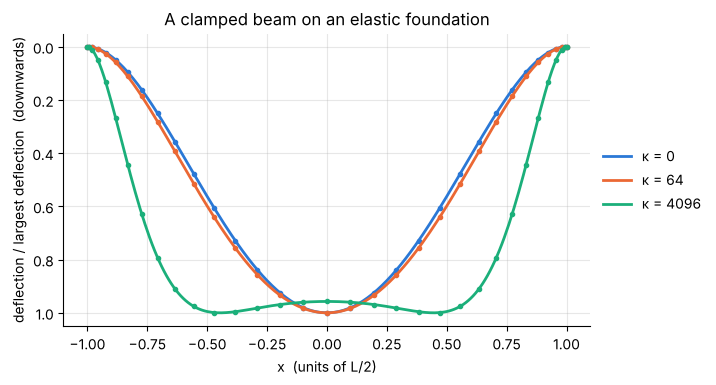

In [6]:
def foundation_exact(kappa, x):
    """Exact deflection of the clamped beam on a foundation of stiffness κ under unit load."""
    if kappa == 0:
        return (1 - x**2) ** 2 / 24
    b = (kappa / 4) ** 0.25
    conditions = np.array([[np.cosh(b) * np.cos(b), np.sinh(b) * np.sin(b)],                    # w(1) = 0
                           [np.sinh(b) * np.cos(b) - np.cosh(b) * np.sin(b),
                            np.cosh(b) * np.sin(b) + np.sinh(b) * np.cos(b)]])                   # w'(1) = 0, divided by β
    A, B = np.linalg.solve(conditions, [-1 / kappa, 0])
    return 1 / kappa + A * np.cosh(b * x) * np.cos(b * x) + B * np.sinh(b * x) * np.sin(b * x)

N = 32
D, x = cheb(N)
xi = x[1:N]
centre = N // 2 - 1                                             # x = 0 is interior point number N/2 - 1
fig, ax = plt.subplots(figsize=(6.8, 3.8))
errors, centre_ratio, overshoot = {}, {}, {}
print("   κ      centre deflection    1/κ            ratio     largest w times κ    largest error")
for kappa in (0, 64, 4096):
    w = solve(clamped_d4(N) + kappa * np.eye(N - 1), np.ones(N - 1))
    values = np.concatenate([[0], w, [0]])                      # add the clamped ends, where w = 0
    curve = barycentric_interpolate(values, x_plot)
    errors[kappa] = np.abs(w - foundation_exact(kappa, xi)).max() / w.max()
    if kappa > 0:
        centre_ratio[kappa], overshoot[kappa] = w[centre] * kappa, curve.max() * kappa
        print(f"{kappa:5d}     {w[centre]:.10f}      {1 / kappa:.10f}   {centre_ratio[kappa]:.5f}       {overshoot[kappa]:.5f}           {errors[kappa]:.1e}")
    else:
        print(f"{kappa:5d}     {w[centre]:.10f}      infinite                                           {errors[kappa]:.1e}")
    line, = ax.plot(x_plot, curve / curve.max(), label=f"κ = {kappa}")
    ax.plot(x, values / curve.max(), "o", ms=3, color=line.get_color())
ax.invert_yaxis()
ax.set(xlabel="x  (units of L/2)", ylabel="deflection / largest deflection  (downwards)",
       title="A clamped beam on an elastic foundation")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5));

In [7]:
# verify: the closed-form solution for each κ, and the overshoot 1 + exp(-π) of a long beam near a clamped end
assert max(errors.values()) < 1e-9
assert abs(centre_ratio[4096] - 1) < 2e-3 and abs(centre_ratio[64] - 0.8559) < 1e-4
assert abs(overshoot[4096] - (1 + np.exp(-np.pi))) < 1e-3 and abs(overshoot[64] - centre_ratio[64]) < 1e-12

**Answer.** The centre deflections are $0.0416667 = 1/24$ for $\kappa = 0$, $0.0133735$ for
$\kappa = 64$ (0.856 of $1/\kappa$) and $0.000243759$ for $\kappa = 4096$ (0.9984 of
$1/\kappa$). With a soft foundation the supports are felt along the whole beam. With a stiff
one the middle of the beam does not know that the supports exist: the springs carry the load
locally and $w = 1/\kappa$ there. The supports matter only in boundary layers of width a few
times $1/\beta = 0.18$. Inside a layer the deflection is a damped oscillation,
$w \approx \kappa^{-1}\big[1 - e^{-\beta s}(\cos\beta s + \sin\beta s)\big]$ with $s$ the
distance from the support, so on its way up from zero it overshoots: the largest deflection is
not at the centre but at $s \approx \pi/\beta$, about 0.55 from each end, and is 4.3 per cent
($e^{-\pi}$) above $1/\kappa$. This is why a footing on stiff ground is designed for the
bending near its ends and not at mid-span.

## Exercise 3

**A simply supported plate.** With $w = 0$ and zero bending moment on every edge of the
square, the plate equation $\nabla^4w = 1$ splits into two Poisson problems,
$\nabla^2m = 1$ and $\nabla^2w = m$, each with zero boundary values (use the Laplacian of
notebook 6). With $N = 24$, compute the centre deflection and confirm the handbook value
$0.00406235\,p\,a^4/D_p$ (that is, $w(0,0) = 0.0649976$ on the square of side 2). By what
factor is the clamped plate stiffer?

This is the two-dimensional version of the simply supported beam of 14.2: two solves with the
same matrix. The handbook value comes from Navier's double sine series, which can be summed
directly as an independent check. For a plate of side $a$,

$$w_{\text{centre}} = \frac{16\,p\,a^4}{\pi^6 D_p}\sum_{m,n\ \text{odd}}
\frac{(-1)^{(m+n)/2 - 1}}{m\,n\,(m^2 + n^2)^2} .$$

In [8]:
N = 24
L, x = laplacian_2d(N)
load = np.ones((N - 1) ** 2)
moment = solve(L, load)                                         # ∇²m = 1, m = 0 on the edges
w_simple = solve(L, moment).reshape(N - 1, N - 1)               # ∇²w = m, w = 0 on the edges
centre = N // 2 - 1                                             # x = 0 and y = 0 are interior point number N/2 - 1
w_centre_simple = w_simple[centre, centre]
w_centre_clamped = solve(plate_operator(N), load).reshape(N - 1, N - 1)[centre, centre]

odd = np.arange(1, 400, 2)
m, n = np.meshgrid(odd, odd)
navier = 16 / np.pi**6 * ((-1.0) ** ((m + n) // 2 - 1) / (m * n * (m**2 + n**2) ** 2)).sum()
print(f"simply supported: w(0,0) = {w_centre_simple:.10f},  w(0,0)/16 = {w_centre_simple / 16:.10f}")
print(f"Navier series:               {16 * navier:.10f},              {navier:.10f}     handbook 0.00406235")
print(f"clamped:          w(0,0) = {w_centre_clamped:.10f},  w(0,0)/16 = {w_centre_clamped / 16:.10f}")
print(f"ratio simply supported / clamped = {w_centre_simple / w_centre_clamped:.4f}")

simply supported: w(0,0) = 0.0649976426,  w(0,0)/16 = 0.0040623527
Navier series:               0.0649976426,              0.0040623527     handbook 0.00406235
clamped:          w(0,0) = 0.0202451054,  w(0,0)/16 = 0.0012653191
ratio simply supported / clamped = 3.2105


In [9]:
# verify: the handbook value, Navier's series summed independently, and the clamped benchmark of 14.5
assert abs(w_centre_simple / 16 - 0.00406235) < 5e-9 and abs(w_centre_simple - 0.0649976) < 5e-8
assert abs(w_centre_simple / 16 - navier) < 1e-11
assert abs(w_centre_clamped / 16 - 0.00126532) < 5e-9

**Answer.** $w(0,0) = 0.0649976426$, that is $0.0040623527\,p\,a^4/D_p$, in agreement with the
handbook value and with Navier's series to all the digits printed. The clamped plate deflects
$0.0202451$, so clamping the edges makes the plate 3.21 times stiffer at the centre. The
corresponding factor for a beam was 5 (14.2): a plate carries load in two directions, so it
gains less from having its edge rotations restrained.

## Exercise 4

**The fundamental frequency of a clamped plate.** Free vibrations of the plate of 14.5
satisfy $\nabla^4w = \lambda w$ with the same boundary conditions. Compute the smallest
eigenvalue of the matrix $L$ of 14.5 with $N = 16$ and $N = 20$, and compare the frequency
parameter $4\sqrt{\lambda_1}$ (which is $\omega a^2\sqrt{\rho h/D_p}$ for a plate of side
$a$) with the handbook value 35.985. What is the multiplicity of the second eigenvalue, and
why?

The matrix is `plate_operator(N)`, of size $(N-1)^2$: 225 and 361 here, small enough for a
dense eigenvalue solver. The collocation matrix is not symmetric, so `eigvals` returns complex
numbers; the true eigenvalues are real and positive, and the imaginary parts measure rounding
error (a double eigenvalue typically comes back as a complex pair split by rounding). Two resolutions tell which digits to believe.

In [10]:
frequencies = {}
for N in (16, 20):
    values = eigvals(plate_operator(N))
    lowest = values[np.argsort(values.real)[:6]]
    frequencies[N] = 4 * np.sqrt(lowest.real)
    print(f"N = {N}: 4√λ = " + "  ".join(f"{f:.5f}" for f in frequencies[N]) + f"     largest |imaginary part| / λ: {np.abs(lowest.imag / lowest.real).max():.0e}")
split = abs(lowest[2] - lowest[1]) / abs(lowest[1])               # as complex numbers, N = 20
print(f"second and third eigenvalues differ by a fraction {split:.0e}")
print(f"ratio of the second frequency to the first: {frequencies[20][1] / frequencies[20][0]:.4f}")

N = 16: 4√λ = 35.98519  73.39385  73.39385  108.21650  131.58077  132.20479     largest |imaginary part| / λ: 4e-13
N = 20: 4√λ = 35.98519  73.39385  73.39385  108.21650  131.58077  132.20479     largest |imaginary part| / λ: 1e-12
second and third eigenvalues differ by a fraction 2e-12
ratio of the second frequency to the first: 2.0396


In [11]:
# verify: the handbook values of the first two frequency parameters (35.985 and 73.394),
# agreement between the two resolutions, and the double second eigenvalue
assert abs(frequencies[20][0] - 35.985) < 5e-4 and abs(frequencies[20][1] - 73.394) < 5e-4
assert np.abs(frequencies[16] - frequencies[20]).max() < 1e-5
assert split < 1e-8 and frequencies[20][3] > 1.4 * frequencies[20][1]

**Answer.** $4\sqrt{\lambda_1} = 35.98519$ with both $N = 16$ and $N = 20$, which rounds to
the handbook value 35.985. The second eigenvalue is **double**: $4\sqrt{\lambda} = 73.39385$
appears twice. The square is unchanged when $x$ and $y$ are exchanged, so a mode with one nodal
line across $x$ has a partner of the same frequency with its nodal line across $y$, and any
combination of the two, such as a mode with a diagonal nodal line, is also a mode. The next
three values, 108.217, 131.581 and 132.205, are simple. For a designer the pair means that a
square panel excited near 2.04 times its fundamental frequency can respond in a pattern that
depends on where it is driven, and a slightly non-square panel splits the pair into two
close frequencies.

## Exercise 5

**The band of unstable wavenumbers.** At $Re = 7500$, compute the largest $c_i$ for 21
equally spaced wavenumbers $0.8 \le \alpha \le 1.2$ with $N = 50$ and plot it. Then use
`brentq` to find the two neutral wavenumbers at which it crosses zero. Repeat at
$Re = 6000$ and describe how the unstable band changes as $Re$ falls towards 5772.

`growth(Re, alpha, N)` of 14.6 is the function to scan and to hand to `brentq`, once on each
side of the wavenumber where the scan is largest. Two checks are available. The neutral
wavenumbers should not move when $N$ is raised to 80. And near the critical point the neutral
curve is a parabola, $Re - Re_c \propto (\alpha - \alpha_c)^2$, so the square of the band
width is linear in $Re$: extrapolating it to zero from the two Reynolds numbers should land
near $Re_c = 5772$, and the band centre should head for $\alpha_c = 1.02056$.

Re = 7500: largest c_i in the scan 0.00229 at α = 0.98;  neutral wavenumbers 0.87474 and 1.09437,  width 0.21963,  centre 0.9846


Re = 6000: largest c_i in the scan 0.00036 at α = 1.02;  neutral wavenumbers 0.97071 and 1.05964,  width 0.08893,  centre 1.0152
change of the neutral wavenumbers from N = 50 to N = 80: 4.7e-08
width² extrapolated to zero: Re = 5706   (critical value 5772);  band centre extrapolated to Re = 5772: α = 1.0198   (1.02056)


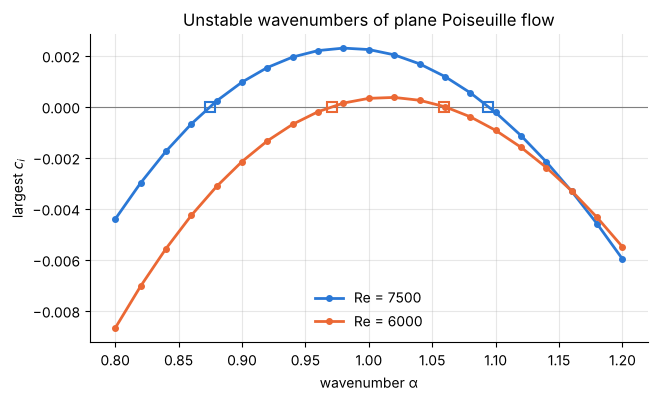

In [12]:
def neutral_wavenumbers(Re, peak, N):
    """The two wavenumbers on either side of `peak` at which the largest c_i is zero."""
    return np.array([brentq(lambda alpha: growth(Re, alpha, N), 0.8, peak, xtol=1e-10),
                     brentq(lambda alpha: growth(Re, alpha, N), peak, 1.2, xtol=1e-10)])

alphas = np.linspace(0.8, 1.2, 21)
fig, ax = plt.subplots(figsize=(7.2, 4))
ax.axhline(0, color="0.5", lw=0.8)
bands, bands_fine = {}, {}
for Re in (7500, 6000):
    c_i = np.array([growth(Re, alpha, 50) for alpha in alphas])
    peak = alphas[c_i.argmax()]
    bands[Re], bands_fine[Re] = neutral_wavenumbers(Re, peak, 50), neutral_wavenumbers(Re, peak, 80)
    line, = ax.plot(alphas, c_i, "o-", ms=4, label=f"Re = {Re}")
    ax.plot(bands[Re], [0, 0], "s", ms=7, mfc="none", mew=1.5, color=line.get_color())
    print(f"Re = {Re}: largest c_i in the scan {c_i.max():.5f} at α = {peak:.2f};  neutral wavenumbers "
          f"{bands[Re][0]:.5f} and {bands[Re][1]:.5f},  width {np.diff(bands[Re])[0]:.5f},  centre {bands[Re].mean():.4f}")
ax.set(xlabel="wavenumber α", ylabel="largest $c_i$", title="Unstable wavenumbers of plane Poiseuille flow")
ax.legend(frameon=False, loc="lower center");

width2 = {Re: np.diff(bands[Re])[0] ** 2 for Re in bands}
Re_c_estimate = 6000 - width2[6000] * (7500 - 6000) / (width2[7500] - width2[6000])
centre_slope = (bands[7500].mean() - bands[6000].mean()) / 1500
alpha_c_estimate = bands[6000].mean() + centre_slope * (5772.2 - 6000)
print(f"change of the neutral wavenumbers from N = 50 to N = 80: {max(np.abs(bands[Re] - bands_fine[Re]).max() for Re in bands):.1e}")
print(f"width² extrapolated to zero: Re = {Re_c_estimate:.0f}   (critical value 5772);  band centre extrapolated to Re = 5772: α = {alpha_c_estimate:.4f}   (1.02056)")

In [13]:
# verify: neutral wavenumbers unchanged at a finer resolution, c_i = 0 changes sign across each of them,
# and the band closes at the known critical point (Re_c = 5772.2, α_c = 1.02056) when extrapolated
for Re in bands:
    assert np.abs(bands[Re] - bands_fine[Re]).max() < 1e-6
    assert growth(Re, bands[Re].mean(), 80) > 0 and growth(Re, bands[Re][0] - 0.01, 80) < 0 and growth(Re, bands[Re][1] + 0.01, 80) < 0
assert bands[7500][0] < bands[6000][0] < 1.02056 < bands[6000][1] < bands[7500][1]
assert abs(Re_c_estimate / 5772.2 - 1) < 0.02 and abs(alpha_c_estimate - 1.02056) < 2e-3

**Answer.** At $Re = 7500$ the flow is unstable for $0.8747 < \alpha < 1.0944$, a band of width
0.2196, with the largest $c_i = 0.0023$ near $\alpha = 0.98$. At $Re = 6000$ the band has
shrunk to $0.9707 < \alpha < 1.0596$, width 0.0889, and the largest $c_i$ is six times
smaller. As $Re$ falls the band narrows from both sides, its centre drifts upwards from 0.985
to 1.015, and the growth rates fall. The width closes like $\sqrt{Re - Re_c}$: extrapolating
its square to zero from these two Reynolds numbers gives $Re \approx 5706$, within about one
per cent of 5772, and the centre extrapolates to $\alpha = 1.020$. Below the critical Reynolds
number there is no unstable wavenumber at all, and just above it only waves about six channel
half-widths long ($2\pi/\alpha_c = 6.2$) can grow.